# Binary Classification with Linear Genetic Programming

Binary Classification is usually a task that we let Machine Learning handle.\
But who says that Linear Genetic Programming cannot try to solve it?

In this notebook, we use Linear Genetic Programming (LGP) to evolve small, assembly-like programs for binary classification.

Unlike a conventional classifier with fixed parameters, an LGP individual is a sequence of instructions that reads and updates a set of registers. Evolution changes these instructions through selection, crossover, and mutation.

We will use a toy dataset for the task, and we will try to visualize what solution our linearGP finds.

In [159]:
import random
import numpy as np
import matplotlib.pyplot as plt
import copy

seed = 37
np.random.seed(seed)
random.seed(seed)

The dataset is composed by two concentric circles. Seems easy, but it can be really difficult to solve!

This task is nonlinear in the original \((x_1,x_2)\) feature space. A compact solution can compare the squared radius \(x_1^2+x_2^2\) with a threshold, so it is a useful test of whether LGP can discover a short arithmetic program.

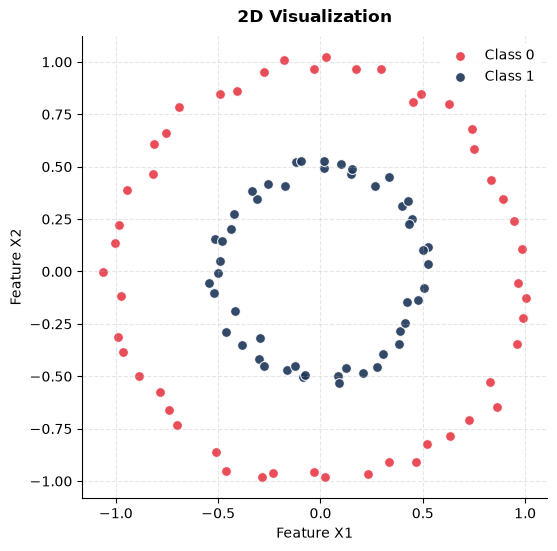

In [ ]:
from sklearn.datasets import make_circles

n_samples = 100
X, y = make_circles(n_samples=n_samples, factor=0.5,noise=0.03)

plt.figure(figsize=(6, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='#e63946', label='Class 0', s=50, edgecolor='white', linewidth=0.8, alpha=0.9)
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='#1d3557', label='Class 1', s=50, edgecolor='white', linewidth=0.8, alpha=0.9)
plt.title("2D Visualization", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Feature X1", fontsize=10)
plt.ylabel("Feature X2", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(frameon=True, facecolor='white', edgecolor='none', framealpha=0.9)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

We represent each classifier as an assembly-like program followed by a threshold on register R0.

For every input sample, the program starts with fresh registers, executes its instructions in order, and returns the final value of R0. The prediction is class 1 when R0 >= 0, and class 0 otherwise.

Each instruction has the form `(operation, destination, source1, source2, constant)`. The operation reads the relevant source registers and writes its result to the destination register.

You can find the addition already defined.

Implement the subtraction, the multiplication and so on.

Remember to add sanity check if necessary!

In [1]:
# Format: lambda r, dest, s1, s2, c
def op_add(regs, d, s1, s2, c): regs[d] = regs[s1] + regs[s2]

# TODO implement other operations, such as sub, mul etc

This helper function translates machine instructions into human-readable assembly-style strings for debugging and inspection.

Everytime you write a new operation remember also to write its corresponding `instruction_string`.

In [ ]:
def instruction_string(instruction, values = None):
    if values:
        v1, v2 = values
    op, dest, s1, s2, c = instruction
    if op == op_add:
        if values:
            return f"R{dest} = R{s1} + R{s2} -> R{dest} = {v1:.2f} + {v2:.2f} = {v1+v2:.2f}"
        return f"R{dest} = R{s1} + R{s2}"
    # TODO implement the instruction string for the operations you have implemented

These constants define the virtual machine and the space from which instructions are sampled:

- `OPERATIONS`: the operations that mutation and initialization can choose.
- `MIN_CONSTANT`, `MAX_CONSTANT`: the range for constants used by instructions.
- `NUM_REGISTERS`: the number of registers available to a program.
- `NUM_INPUTS`: the number of input features (the inputs are stored in `R1` and `R2`).
- `N_OPS`: the default number of instructions in each program.

The number of defined operations is not necessarily the number of operations available to evolution. Check `OPERATIONS` for the active set.

In [ ]:
OPERATIONS = [op_add]
MIN_CONSTANT = -2
MAX_CONSTANT = 2
NUM_REGISTERS = 4
NUM_INPUTS = 2  # R1, R2

N_OPS = 5

Now we can think at the program representation itself.

The `LGPProgram` class represents an individual in our evolutionary population. It stores a sequence of instructions, executes them across working registers initialized with input features, and returns a binary prediction thresholded at register 0.

The final rule is class 1 if R0 >= 0, otherwise class 0. Keep this convention consistent in the prediction method, program string, and plots.

Notice again: R0 is the register where we store the value we will use to compute the threshold in the end. R1 will contains the x1 and the R2 will contains the x2. R0 and all the other registers (with the exception of R1 and R2) will be initialized to 0.

In [164]:
class LGPProgram:
    def __init__(self, length=N_OPS):
        self.instructions = []
        for _ in range(length):
            op = random.choice(OPERATIONS)
            dest = random.randint(0, NUM_REGISTERS - 1)
            s1 = random.randint(0, NUM_REGISTERS - 1)
            s2 = random.randint(0, NUM_REGISTERS - 1)
            c = random.uniform(MIN_CONSTANT, MAX_CONSTANT)
            self.instructions.append((op, dest, s1, s2, c))
        self.fitness = 0.0

    def execute(self, sample, verbose = False):
        # Initialize registers: Ri = 0 for all i, except for R1 = x1, R2 = X2
        regs = np.zeros(NUM_REGISTERS)
        regs[1] = sample[0]
        regs[2] = sample[1]
        
        for instruction in self.instructions:
            try:
                op, dest, s1, s2, c = instruction
            except Exception as e:
                print(e)
                print(instruction)
            try:
                op(regs, dest, s1, s2, c)
            except Warning as w:
                print(f"operation : {instruction_string(instruction)} raised a warning")
                print(regs[dest])
                print(regs[s1])
                print(regs[s2])
                print(c)
            if verbose:
                print(f"Instruction : {instruction_string(instruction, values=(regs[s1], regs[s2]))}")
                print("Register state :",end="")
                for i, reg in enumerate(regs):
                    print(f"R{i}={reg:.2f} ",end="")
                print()
                print("-------------------------------------------------")
        # Return output from R0
        return regs[0]

    def predict(self, X, verbose = False):
        preds = []
        for sample in X:
            out = self.execute(sample, verbose=verbose)
            # Threshold at 0 for binary classification
            preds.append(1 if out >= 0 else 0)
        return np.array(preds)

    def __str__(self):
        s = ""
        for instruction in self.instructions:
            s+=instruction_string(instruction)
            s+="\n"
        s+=f"return (R0 < 0) ? 0 : 1"
        return s

Here you must define fitness, crossover and mutation.\
Fitness is the fraction of training examples classified correctly (training accuracy). Crossover combines segments of two instruction sequences, while mutation replaces individual instructions with randomly generated ones.

In [ ]:
def calculate_fitness(program, X, y):
    # TODO 
    pass

def crossover(p1, p2):
    # TODO
    pass

def mutate(program, mutation_rate=0.2):
    # TODO
    pass

And now implement the evolutionary search process over multiple generations, tracking the best accuracy and evolving the population toward a high-performing classifier.

Implement also elitism and the tournament selection.

In [ ]:
def run_lgp(X, y, generations=50, pop_size=100, mutation_rate=0.2, elitism=False, k_turnament=3):
    # Initialize population
    population = ...
    
    best_overall = None
    best_fitness = -1.0

    history_records = []
    
    for gen in range(generations):
        # Evaluate fitness
        # TODO 

        history_records.append((copy.deepcopy(best_overall), best_fitness, gen + 1))
                
        print(f"Generation {gen+1:02d} | Best Accuracy: {best_fitness:.4f}")
        
        if best_fitness == 1.0:
            print("Perfect accuracy reached!")
            break
            
        # Selection & Reproduction (Elitism + Tournament)
        # TODO 
        new_population = ...

        while len(new_population) < pop_size:
            # TODO 
            # Tournament selection
            # Crossover
            # Mutation
            ... 

        # Update population
        population = ...
        
    return best_overall, history_records

And we can now run everything.

Here we have some parameters alread setted, you can tweak them!

In [167]:
generations = 300
pop_size = 200
mutation_rate = 0.15
elitism = True
k_turnament = 3
# Run the evolutionary training
best_program, history_records = run_lgp(X, y, generations, pop_size, mutation_rate, elitism, k_turnament)

Generation 01 | Best Accuracy: 0.5200
Generation 02 | Best Accuracy: 0.5900
Generation 03 | Best Accuracy: 0.6500
Generation 04 | Best Accuracy: 0.6500
Generation 05 | Best Accuracy: 0.6500
Generation 06 | Best Accuracy: 0.6600
Generation 07 | Best Accuracy: 0.6600
Generation 08 | Best Accuracy: 0.7300
Generation 09 | Best Accuracy: 0.7300
Generation 10 | Best Accuracy: 0.7300
Generation 11 | Best Accuracy: 0.7300
Generation 12 | Best Accuracy: 0.7300
Generation 13 | Best Accuracy: 0.7300
Generation 14 | Best Accuracy: 0.7800
Generation 15 | Best Accuracy: 0.7800
Generation 16 | Best Accuracy: 0.7800
Generation 17 | Best Accuracy: 0.7800
Generation 18 | Best Accuracy: 0.7800
Generation 19 | Best Accuracy: 0.7800
Generation 20 | Best Accuracy: 0.7800
Generation 21 | Best Accuracy: 0.7800
Generation 22 | Best Accuracy: 0.7800
Generation 23 | Best Accuracy: 0.7800
Generation 24 | Best Accuracy: 0.8000
Generation 25 | Best Accuracy: 0.8000
Generation 26 | Best Accuracy: 0.8000
Generation 2

And now let's print and visualize the best program found so far.

In [168]:
print(best_program)
print()
best_program.predict([[1, 1]], verbose=True)

R3 = R1 x R1
R1 = R2 x R2
R2 = 0.33
R1 = R3 + R1
R0 = R2 - R1
return (R0 < 0) ? 0 : 1

Instruction : R3 = R1 x R1 -> R3 = 1.00 x 1.00 = 1.00
Register state :R0=0.00 R1=1.00 R2=1.00 R3=1.00 
-------------------------------------------------
Instruction : R1 = R2 x R2 -> R1 = 1.00 x 1.00 = 1.00
Register state :R0=0.00 R1=1.00 R2=1.00 R3=1.00 
-------------------------------------------------
Instruction : R2 = 0.33 -> R2 = 0.33
Register state :R0=0.00 R1=1.00 R2=0.33 R3=1.00 
-------------------------------------------------
Instruction : R1 = R3 + R1 -> R1 = 1.00 + 2.00 = 3.00
Register state :R0=0.00 R1=2.00 R2=0.33 R3=1.00 
-------------------------------------------------
Instruction : R0 = R2 - R1 -> R0 = 0.33 - 2.00 = -1.67
Register state :R0=-1.67 R1=2.00 R2=0.33 R3=1.00 
-------------------------------------------------


array([0])

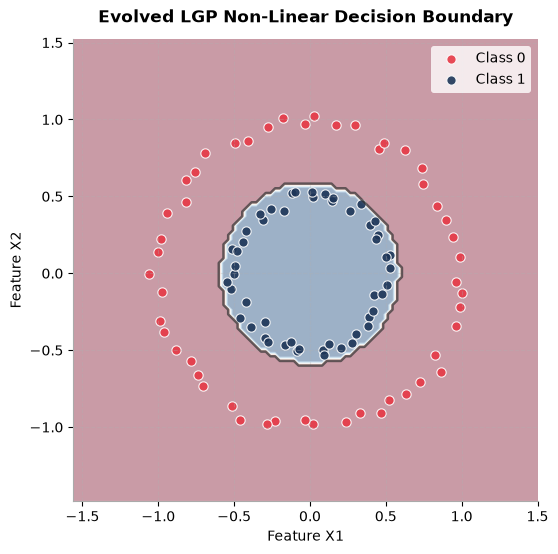

In [169]:
def plot_decision_boundary(model, X, y):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))
    
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)
    
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Soft background regions and crisp decision line
    ax.contourf(xx, yy, Z, levels=20, alpha=0.4, cmap='RdBu', antialiased=True)
    ax.contour(xx, yy, Z, levels=[0], colors='#333333', linewidths=1.8, alpha=0.7)
    
    mask_0 = (y == 0)
    mask_1 = (y == 1)
    ax.scatter(X[mask_0, 0], X[mask_0, 1], c='#e63946', label='Class 0', s=45, edgecolor='white', linewidth=0.8, alpha=0.9)
    ax.scatter(X[mask_1, 0], X[mask_1, 1], c='#1d3557', label='Class 1', s=45, edgecolor='white', linewidth=0.8, alpha=0.9)
    
    ax.set_title("Evolved LGP Non-Linear Decision Boundary", fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel("Feature X1", fontsize=10)
    ax.set_ylabel("Feature X2", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none', framealpha=0.8)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_color('#aaaaaa')
        
    plt.show()

plot_decision_boundary(best_program, X, y)

Let's also try to visualize the evolution of the best solution found during the optimization process.

In [170]:
import copy
import matplotlib.animation as animation
from IPython.display import HTML

def run_lgp_with_matplotlib_animation(X, y, history_records):
    # --- Build Polished GIF Animation using Matplotlib Animation Framework ---
    fig, ax = plt.subplots(figsize=(6, 6))
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    def update_frame(frame_idx):
        ax.clear()
        program, fit, gen_num = history_records[frame_idx]
        
        Z = program.predict(grid_points).reshape(xx.shape)
        
        # Soft background and crisp decision line
        ax.contourf(xx, yy, Z, levels=20, alpha=0.4, cmap='RdBu', antialiased=True)
        ax.contour(xx, yy, Z, levels=[0], colors='#333333', linewidths=1.8, alpha=0.7)
        
        mask_0 = (y == 0)
        mask_1 = (y == 1)
        ax.scatter(X[mask_0, 0], X[mask_0, 1], c='#e63946', label='Class 0', s=45, edgecolor='white', linewidth=0.8, alpha=0.9)
        ax.scatter(X[mask_1, 0], X[mask_1, 1], c='#1d3557', label='Class 1', s=45, edgecolor='white', linewidth=0.8, alpha=0.9)
        
        ax.set_title(f"Generation {gen_num:02d}  |  Accuracy: {fit * 100:.1f}%", fontsize=12, fontweight='bold', pad=12)
        ax.set_xlabel("Feature X1", fontsize=10)
        ax.set_ylabel("Feature X2", fontsize=10)
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none', framealpha=0.8)
        
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        for spine in ['bottom', 'left']:
            ax.spines[spine].set_color('#aaaaaa')

    anim = animation.FuncAnimation(fig, update_frame, frames=len(history_records), interval=250)
    
    gif_path = "lgp_evolution.gif"
    anim.save(gif_path, writer='pillow', fps=4)
    plt.close(fig)
    
    print(f"\nPolished evolutionary animation successfully saved as '{gif_path}'!")

    return HTML(f'<img src="{gif_path}" alt="LGP Evolution GIF">')

Sometimes you have to close and reopen the notebook in order to visualize it.

In [ ]:
display(run_lgp_with_matplotlib_animation(X, y, history_records))


Polished evolutionary animation successfully saved as 'lgp_evolution.gif'!
